# Teorema do Limite Central

**Autor**: Carlos Gabriel de Oliveira Campos

**Professor**: Dr. Daniel Roberto Cassar

Monstro: Mímico

O teorema do limite central afirma que dado um conjunto de simulações que seguem uma mesma distribuição — de variância finita e cujos valores são independentes entre si —, quanto maior o número de amostras, a distribuição dos valores de média das simulações tende a seguir uma distribuição normal. 

---

O Teorema do Limite Central é importantíssimo para probabilidade e estatística;
em especial, é a base de diversos testes de hipóteses. Sua tarefa é se informar sobre
esse teorema, explicá‑lo com suas palavras de maneira clara e explorá‑lo através de
simulações em Python, com gráficos. Sua exploração deve incluir:
• Pelo menos três distribuições de origem claramente não normais (por exemplo,
exponencial, uniforme e uma distribuição bimodal).
• A evolução da distribuição das médias amostrais conforme o tamanho da amostra
𝑛 aumenta.
• A comparação de cada histograma do passo anterior com a curva normal prevista
pelo teorema, com média 𝜇 e desvio padrão 𝜎/√𝑛.
Desafio opcional: repita a simulação com a distribuição de Cauchy. O que acon
tece? Explique por que o teorema não se aplica nesse caso.

## Função suporte

Fornecida pelo professor Daniel de Probabilidade e Estatística [1]. 

In [1]:
import numpy as np
from math import pi
from numpy import exp
import seaborn as sns
import pandas as pd
import matplotlib.pyplot as plt


def dist_normal_pdf(x, media, desvio_padrao):
    """Computa a pdf de uma distribuição normal."""

    preexp = 1 / (desvio_padrao * (2 * pi) ** (1 / 2))
    exp_ = exp(-(1 / 2) * ((x - media) / desvio_padrao) ** 2)
    densidade_prob = preexp * exp_

    return densidade_prob

## Distribuição Normal

Afinal, o que é uma distribuição normal? O que há de tão especial sobre ela?

A dsitribuição normal, também conhecida como distribuição gaussiana, é uma distribuição de probabilidade contínua que apresenta simetria em torno de sua média, sendo que valores próximos a essa média apresentam uma maior probabilidade. Uma distribuição de valores que segue esse comportamento pode ser representada pela notação $X \sim \mathcal{N}(\mu, \sigma^2)$, em que $\mu$ e $\sigma^2$ indicam a média e a variância, respectivamente, sendo que ela é definida matematicamente conforme 

$$
f(x\,|\,\mu,\sigma) = \frac{1}{\sigma \sqrt{2 \pi}} \exp \left( -\frac{1}{2} \left( \frac{x - \mu}{\sigma} \right)^2 \right)
$$


Mais notavelmente, essa distribuição tem seu formato extremamente reconhecido nas áreas da estatística, o qual assemelha-se a de um sino (código fornecido pelo professor Daniel [1]).

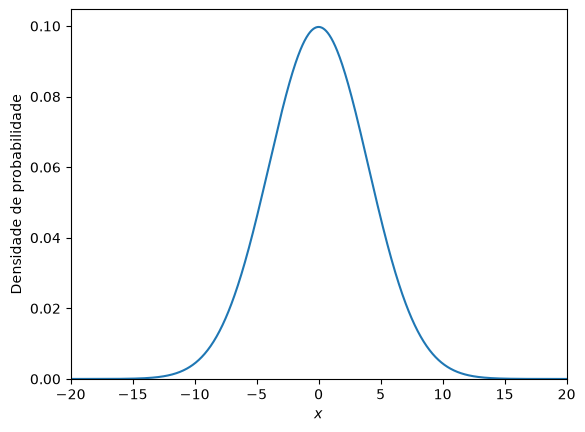

In [2]:
XMIN = -20
XMAX = 20

x = np.linspace(XMIN, XMAX, 1000)
y = dist_normal_pdf(x=x, media=0, desvio_padrao=4)

eixo = sns.lineplot(x=x, y=y)

eixo.set_xlim([XMIN, XMAX])
eixo.set_ylim(bottom=0)

eixo.set_xlabel("$x$")
eixo.set_ylabel("Densidade de probabilidade");

Investiguemos como ela se parece com diferentes parâmetros (código adaptado do material do professor Daniel [1]).

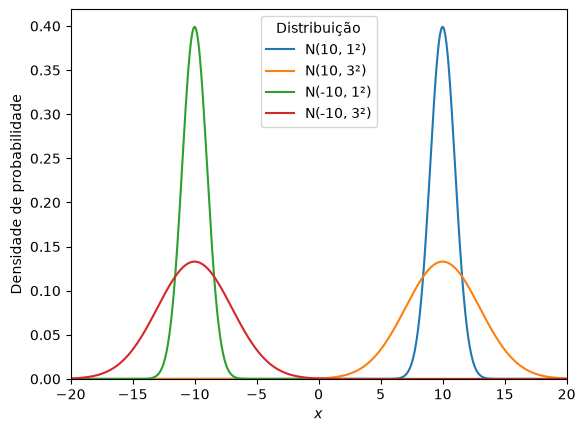

In [3]:
MEDIAS_E_DESVIOS_PADROES = [
    (10, 1),
    (10, 3),
    (-10, 1),
    (-10, 3)
]

x = np.linspace(XMIN, XMAX, 1000)

dados = []

for media, desvio_padrao in MEDIAS_E_DESVIOS_PADROES:
    y = dist_normal_pdf(x, media, desvio_padrao)
    df = pd.DataFrame(
        {
            "x": x,
            "y": y,
            "Distribuição": f"N({media}, {desvio_padrao}²)",
        }
    )
    dados.append(df)

df = pd.concat(dados)

eixo = sns.lineplot(data=df, x="x", y="y", hue="Distribuição")

eixo.set_xlim([XMIN, XMAX])
eixo.set_ylim(bottom=0)

eixo.set_xlabel("$x$")
eixo.set_ylabel("Densidade de probabilidade");

Veja, a média desloca a distribuição pelo eixo x, ao passo que o desvio padrão define o quão concentrada ou dispersa a distribuição estará ao redor da média. 

No mais, outra grande propriedade da distribuição normal é apresentar 68% dos dados a até um desvio padrão de distância da média, 95%, a até dois desvios padrões de distância, e 99.7%, a até três desvios padrões de distância, como mostra a seguinte figura.

<figure align="center">
   <img src="pctg_normal_dist.png" alt="Distribuição Normal" height="400px">

  <figcaption style="font-size: 0.9em; margin-top: 5px;"> 
  Fonte: https://www.geeksforgeeks.org/maths/normal-distribution/ </figcaption>
</figure>


## Entendo o Teorema

Certo, mas como essa distribuição se relaciona ao Teorema do Limite Central? 

O Teorema do Limite Central (TLC) afirma que dado um conjunto de amostras que seguem uma mesma distribuição — de variância finita e cujos valores são independentes entre si —, quanto maior o número de amostras, a distribuição dos valores de média das amostras segue uma *distribuição normal* desde que o tamanho de cada amostra seja suficientemente grande.

Além disso, são importantes 3 premissas-base para esse teorema, sendo que $X_i$ representa os valores da distribuição populacional:

1. Independência entre os valores de $X_i$;
2. Todas as amostras seguem a mesma distribuição populacional;
3. A variância da distribuição populacional é finita.

De primeira, isso de fato é muita informação para compreender bem! Vamos construir o entendimento passo a passo:

## Nos guiando pela sorte de dados

A distribuição populacional é aquela que rege as amostras — que podem ser simulações ou eventos naturais, como o lançamento de dados! Nesse contexto, $X_i$ é represetnado pelo resultado do dado. Em um dado honesto, cada resultado é equiprovável, logo, em um dado de 6 faces, cada face tem $\dfrac{1}{6}$ de probabilidade. Vamos realizar e visualizar simulações!

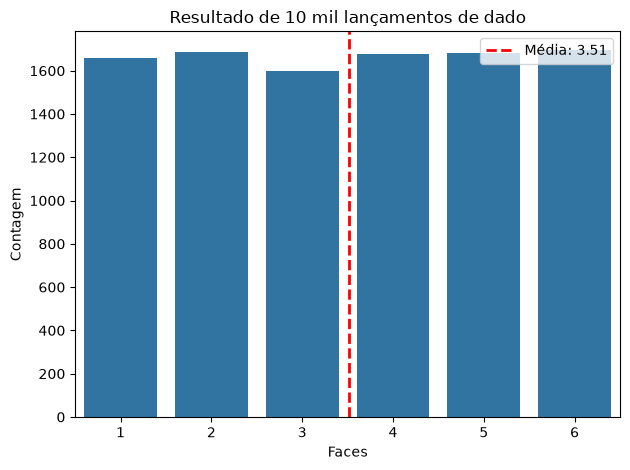

In [71]:
def simula_dados(num_lancamentos: int, pesos=None, mostra_fig=False) -> float:
    """Retorna média de resultados de N lançamentos de 1 dado."""
    
    faces = np.arange(1, 7)
    
    if pesos:
        x = np.random.choice(a=faces, size=num_lancamentos, p=pesos)
    else:
        x = np.random.choice(a=faces, size=num_lancamentos)

    if mostra_fig:
        eixo = sns.countplot(x=x)

        eixo.axvline(x.mean() - 1, color="red", linestyle="--", linewidth=2, label=f"Média: {x.mean():.2f}")
        eixo.legend()

        eixo.set(
            ylabel="Contagem",
            xlabel="Faces",
            title=f"Resultado de {num_lancamentos// 1000} mil lançamentos de dado"
        )
        plt.tight_layout()
        plt.show()

    return x.mean()

media = simula_dados(10_000, mostra_fig=True)

Como era de se esperar, vimos uma contagem muito semelhante entre todas os faces, e o valor da média aproximou-se muito do valor esperado para essa distribuição discreta, que é de 3.5. Agora, façamos um experimento com 10 mil amostras de 10 mil lançamentos de dados em que registramos a média de cada amostra, apresentando ao final a distribuição do valor dessas médias. 

Será agora definida uma função que realiza uma determinada amostragem de $M$ chamadas da função de distribuição populacional com $N$ simulações cada, registrando a média de cada uma dessas $N$ chamadas para então calcular a média agregada de todo o conjunto $M \times N$ de médias registradas. Por fim, é retornado o gráfico com a distribuição das médias correspondente.

In [103]:
def experimento(
    distribuicao_populacional,
    tamanho_amostragem: int,
    num_simulacoes: int,
    ax=None,
    **kwargs
):
    """ Gera M amostras de N simulações e registra a média de cada amostra, 
    apresentando histograma das médias no eixo (ax) fornecido.
    """

    medias = []
    for _ in range(tamanho_amostragem):
        # Supondo que a distribuicao_populacional aceita mostra_fig, garantimos que ela não plote nada interno
        kwargs_sim = kwargs.copy()
        if 'mostra_fig' in kwargs_sim:
            kwargs_sim['mostra_fig'] = False
            
        media = distribuicao_populacional(num_simulacoes, **kwargs_sim)
        medias.append(media)

    # Se nenhum eixo foi passado, cria um novo
    if ax is None:
        fig, ax = plt.subplots()

    # Passamos o 'ax' explicitamente para o seaborn desenhar no lugar certo
    sns.histplot(medias, ax=ax)

    media_agregada = np.mean(medias)

    ax.axvline(
        media_agregada, 
        color="red", 
        linestyle="--", 
        linewidth=2, 
        label=f"Média: {media_agregada:.4f}"
    )

    titulo = (
        f"{distribuicao_populacional.__name__}\n"
        f"Amostras: {tamanho_amostragem} | Simulações: {num_simulacoes}"
    )
    
    ax.set(
        title=titulo,
        xlabel="Valor da média",
        ylabel="Contagem"
    )
    ax.legend()
    
    # Retorna o eixo para possíveis manipulações posteriores
    return ax

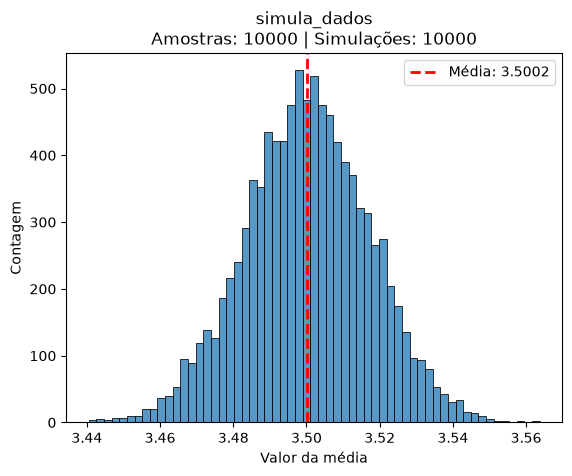

In [105]:
TAMANHO_AMOSTRAGEM= 10_000
NUM_SIMULACOES = 10_000

experimento(
    distribuicao_populacional=simula_dados,
    tamanho_amostragem = TAMANHO_AMOSTRAGEM,
    num_simulacoes = NUM_SIMULACOES
);

Podemos muito enxergar a formação de uma distribuição normal!! É sobre isso de que se trata o TLC: 

- Definimos uma distribuição (lançamento de dados)
- Realizamos simulações dessas distribuição (uma amostra - a função `simula_dados`)
- Geramos várias dessas amostras (função `experimento`)
- Verificamos a média de cada uma delas (plotamos as médias)

Outro ponto interessante é que esse resultado independe da "honestidade" dos dados. Por exemplo, simulemos um dado cuja porbabilidade correspondente às suas faces seja:

1: 5% 
2:30%
3:10%
4: 13%
5: 5%
6: 37%

Vejamos qual é a média dos resultados para esse novo dado viciado a partir de 10 mil simulações, tendo confiança com base na Lei dos Grandes Números (para saber mais sobre isso, visite [2]).

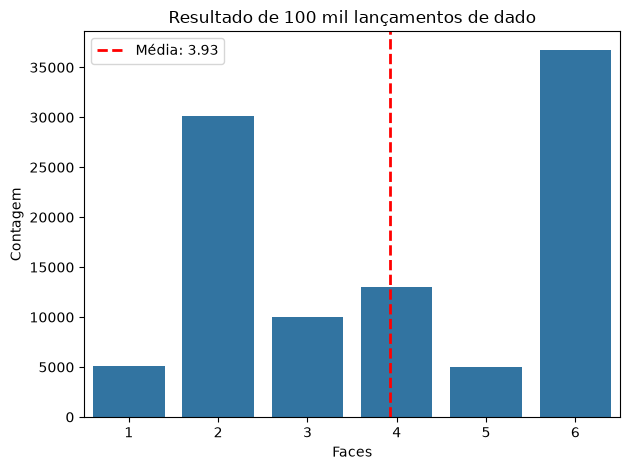

Média da amostra: 3.92905


In [128]:
pesos_viciados = [0.05, 0.3, 0.1, 0.13, 0.05, 0.37]
media_dados_viciados = simula_dados(num_lancamentos=100_000, pesos=pesos_viciados, mostra_fig=True);
print(f"Média da amostra: {media_dados_viciados}")

Agora façamos um experimento com 10 mil dessas amostras

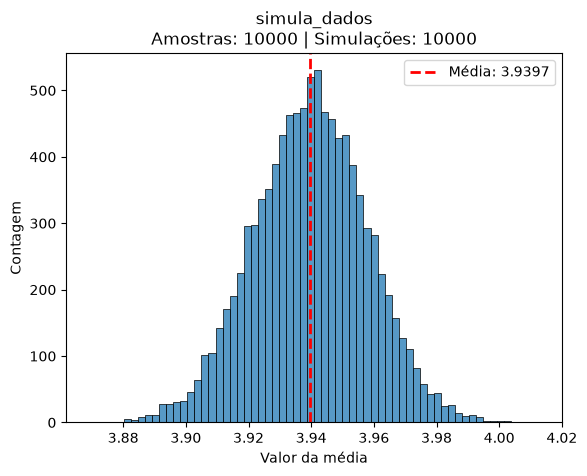

In [107]:
experimento(
    distribuicao_populacional=simula_dados,
    num_simulacoes=10_000,
    tamanho_amostragem=10_000,
    pesos=pesos_viciados
    );

Ademais, um ponto que pode ter passado despercebido na leitura da definição do Teorema do Limite Central é o trecho final: "desde que o tamanho de cada amostra seja suficientemente grande". Essa ressalva é muito importante, pois quando há poucas simulações por chamada $(N)$, a distribuição resultante das médias pode na verdade parecer muito diferente de uma distribuição normal. Assim, vamos dar uma olhada na evolução da distribuição conforme o número de simulações cresce de 1 até 250.

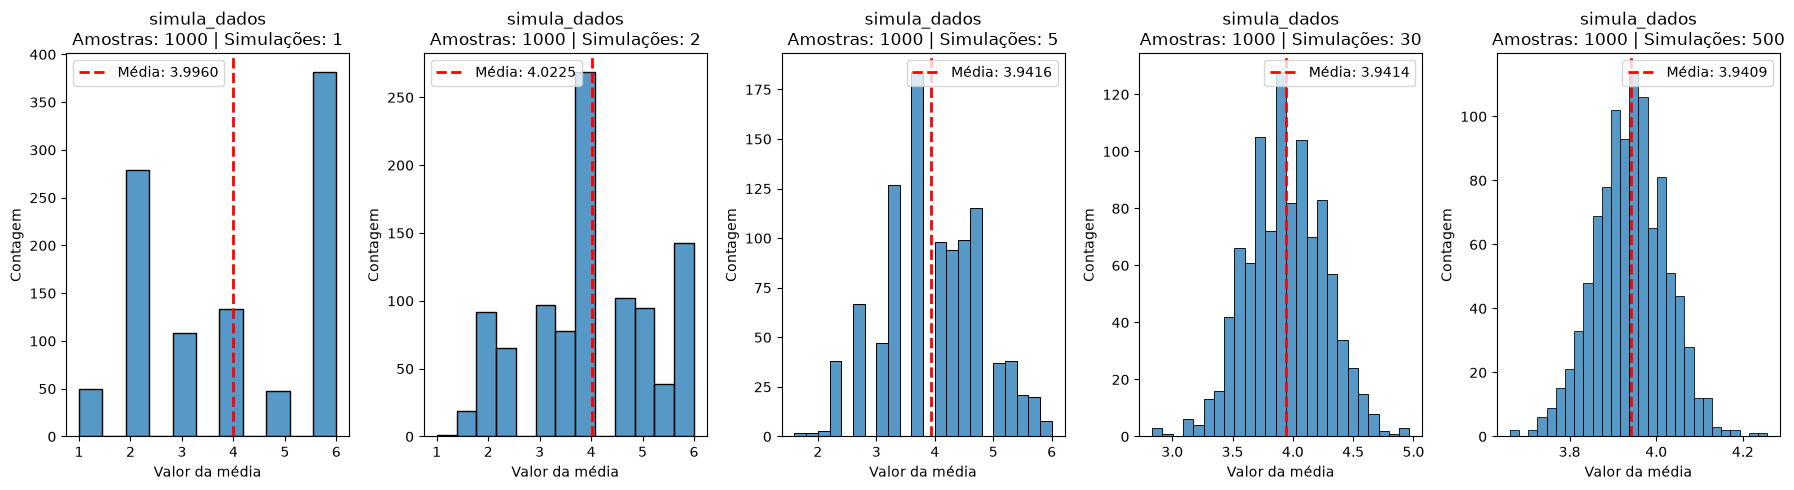

In [117]:
NUM_GRAFICOS = 5
fig, eixos = plt.subplots(1, NUM_GRAFICOS, figsize=(18, 5))

lista_num_simulacoes = (1, 2, 5, 30, 500)

for i in range(NUM_GRAFICOS):
    experimento(
        simula_dados,
        num_simulacoes=lista_num_simulacoes[i], 
        tamanho_amostragem=1_000,
        ax=eixos[i],
        pesos=pesos_viciados
)

plt.tight_layout()
plt.show()

Aha!! Fica evidente que quando $N = 1$, a distribuição das médias geradas reflete muito bem a distribuição populacional, visto que cada chamada opera como apenas uma simulação. Conforme $N$ cresce, fica nítido que a distribuição das médias aproxima-se do formato de uma distribuição normal, como esperado de acordo com o que afirma o Teorema do Limite Central. Além dessa "convergência" no formato, a média da distribuição também aproxima-se do valor esperado teórico para a distribuição populacional, o qual pode ser calculado a partir de 

$$
\text{E}[X] = \sum_{i=1}^{n} p(x_i) \cdot x_i 
$$

In [131]:
valor_esperado = 0
for i in range(1, 7):
    valor_esperado += i * pesos_viciados[i - 1]
print(f"Valor esperado para o lançamento do dado viciado: {valor_esperado}")

Valor esperado para o lançamento do dado viciado: 3.94


## Outras distribuições

Além do ato de lançar dados, podemos nos guiar por este conceito por meio de outras distribuições, até mesmo contínuas, como a distribuição de poisson! Vamos simulá-la para ver como ela se parece.

### Distribuição de Poisson

A distribuição de Poisson é dada por 

$$
f(x\,|\, \mu)=\begin{cases}
\frac{e^{-\mu}\mu^x}{x!} & x=0,1,2\ldots\\
0 & \textrm{caso contrário}
\end{cases}
$$

Definindo função para gerar simulação da distribuiçaõ de Poisson:

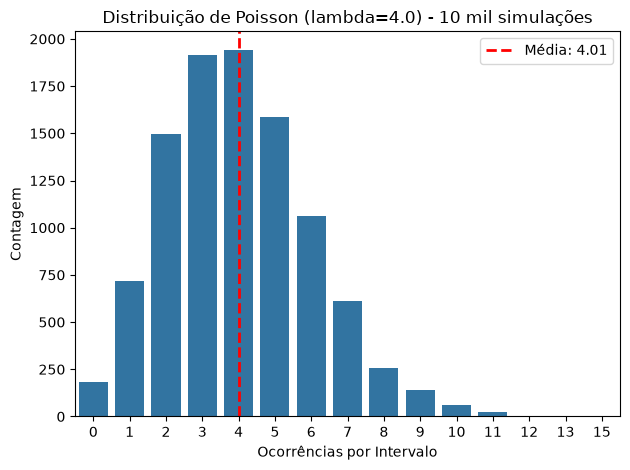

Média da amostra: 4.0051


In [109]:
def simula_poisson(num_simulacoes: int, lam=5.0, mostra_fig=False) -> float:
    """Simula N eventos de uma distribuição de Poisson e retorna a média."""
    
    x = np.random.poisson(lam=lam, size=num_simulacoes)
    
    if mostra_fig:
        plt.figure()
        # countplot ou histplot para variáveis discretas
        eixo = sns.countplot(x=x)
        
        eixo.axvline(x.mean() - x.min(), color="red", linestyle="--", linewidth=2, label=f"Média: {x.mean():.2f}")
        eixo.legend()
        
        eixo.set(
            ylabel="Contagem",
            xlabel="Ocorrências por Intervalo",
            title=f"Distribuição de Poisson (lambda={lam}) - {num_simulacoes // 1_000} mil simulações"
        )
        plt.tight_layout()
        plt.show()

    return x.mean()

# 1. Testando a simulação individual
VAL_LAMBDA = 4.0
media_poisson = simula_poisson(10_000, lam=VAL_LAMBDA, mostra_fig=True)
print(f"Média da amostra: {media_poisson}")

Iremos agora realizar um experimento com 10 mil amostras de 10 mil simulações cada.

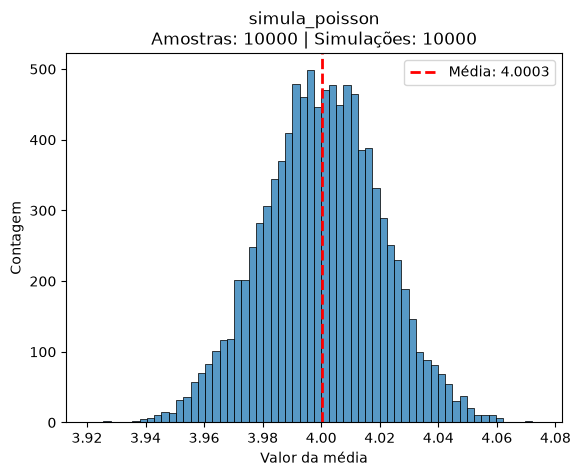

In [110]:
experimento(
    distribuicao_populacional=simula_poisson,
    num_simulacoes=NUM_SIMULACOES,
    tamanho_amostragem=TAMANHO_AMOSTRAGEM,
    lam=VAL_LAMBDA
    );

Quanto à evolução para a distribuição de Poisson:

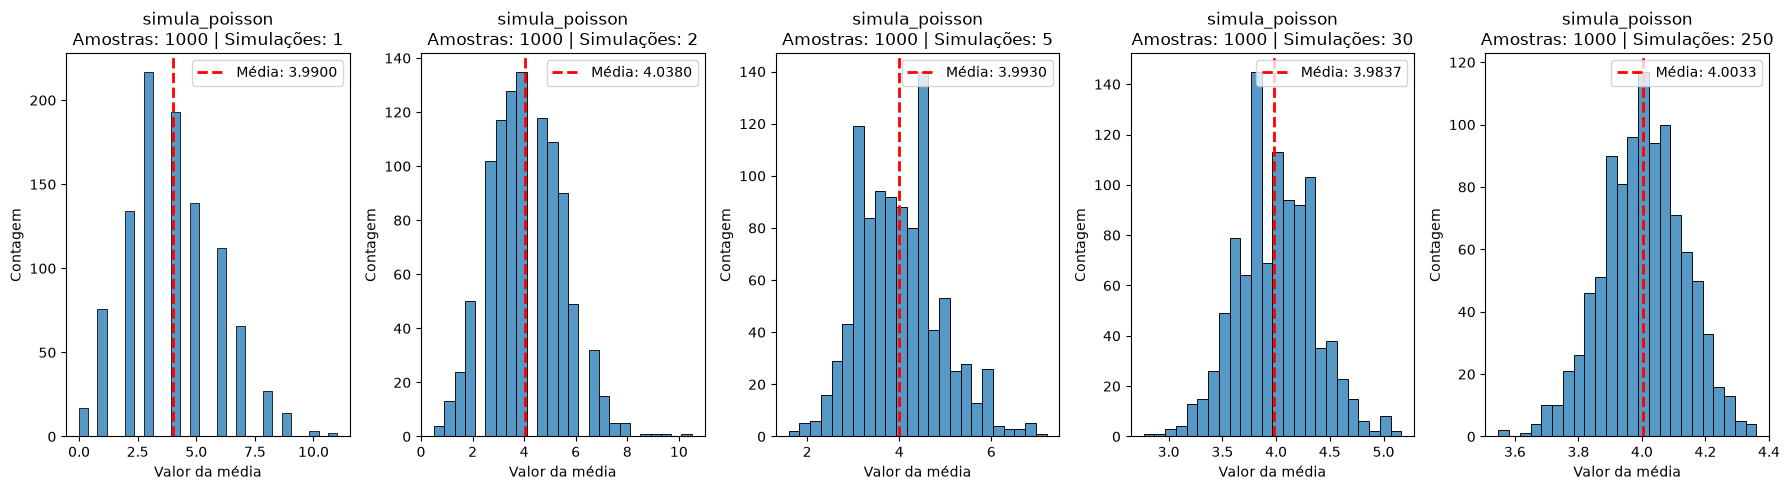

In [111]:
NUM_GRAFICOS = 5
fig, eixos = plt.subplots(1, NUM_GRAFICOS, figsize=(18, 5))

lista_num_simulacoes = (1, 2, 5, 30, 250)

for i in range(NUM_GRAFICOS):
    experimento(
        simula_poisson,
        num_simulacoes=lista_num_simulacoes[i], 
        tamanho_amostragem=1_000,
        lam=VAL_LAMBDA,
        ax=eixos[i]
)

plt.tight_layout()
plt.show()

De acordo com [3 https://en.wikipedia.org/wiki/Poisson_distribution], o valor esperado para a distribuição de Poisson é o próprio $\lambda$, nesse caso, 4, o que concorda com nossas simulações.

## Distribuição exponencial

A dsitribuição exponencial é definida pela 
$$
f(x\,|\, \lambda)=\begin{cases}
\lambda e^{-\lambda x} & x \geq 0\\
0 & \textrm{caso contrário}
\end{cases}
$$

Cujo valor esperado é conhecido e vale $\dfrac{1}{\lambda}$, de acordo com [4  https://en.wikipedia.org/wiki/Exponential_distribution], sendo que para o código, chama-se de *escala* essa razão.

Vamos ver um exemplo.

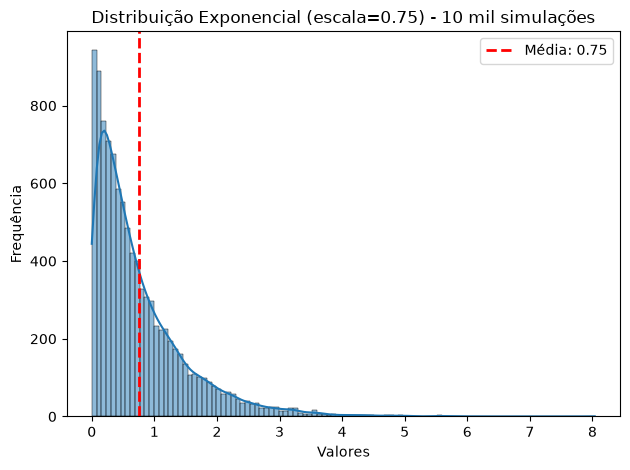

Média da amostra: 0.7534117824748005


In [112]:
def simula_exponencial(num_simulacoes: int, escala=1.0, mostra_fig=False) -> float:
    """Simula N eventos de uma distribuição exponencial e retorna a média."""
    
    x = np.random.exponential(scale=escala, size=num_simulacoes)
    
    if mostra_fig:
        plt.figure()
        eixo = sns.histplot(x, kde=True)
        
        eixo.axvline(x.mean(), color="red", linestyle="--", linewidth=2, label=f"Média: {x.mean():.2f}")
        eixo.legend()
        
        eixo.set( 
            ylabel="Frequência",
            xlabel="Valores",
            title=f"Distribuição Exponencial (escala={escala}) - {num_simulacoes // 1_000} mil simulações"
        )
        plt.tight_layout()
        plt.show()

    return x.mean()

VALOR_ESCALA = 0.75
media_exponencial = simula_exponencial(NUM_SIMULACOES, escala=VALOR_ESCALA, mostra_fig=True)
print(f"Média da amostra: {media_exponencial}")

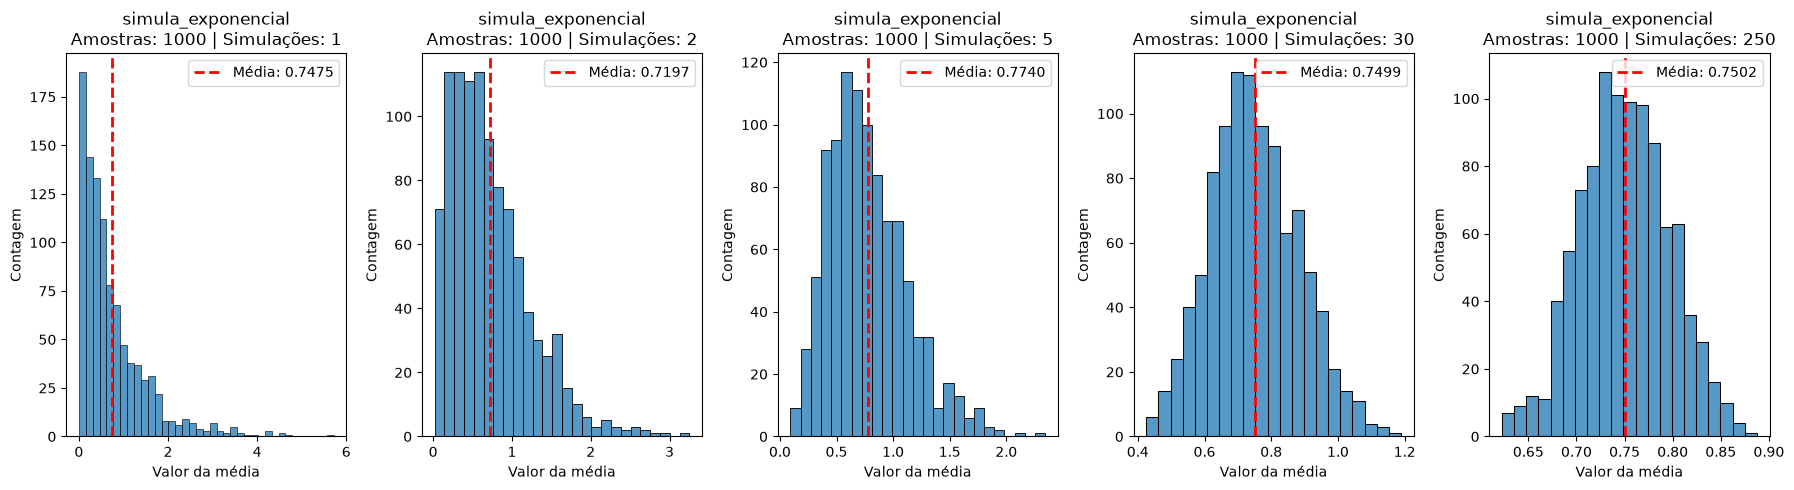

In [113]:
NUM_GRAFICOS = 5
fig, eixos = plt.subplots(1, NUM_GRAFICOS, figsize=(18, 5))

lista_num_simulacoes = (1, 2, 5, 30, 250)

for i in range(NUM_GRAFICOS):
    experimento(
        simula_exponencial,
        num_simulacoes=lista_num_simulacoes[i], 
        tamanho_amostragem=1_000,
        escala=VALOR_ESCALA,
        ax=eixos[i]
)

plt.tight_layout()
plt.show()

## Conclusão

## Referências

[1] CASSAR, Daniel R. Material de aula **LMA-203 7.0 - Distribuição de probabilidades contínuas** para a disciplina de Estatística, 2026.

[2] **Law of Large Numbers**. GeeksforGeeks, 26 jul. 2026. Disponível em: https://www.geeksforgeeks.org/data-science//law-of-large-numbers/. Acesso em: 26 out. 2026.

## Uso de IA neste trabalho

A ferramente de inteligência artificial Gemini foi utilizada para auxiliar a:

- 

<div style="width: 100%; text-align: center; margin-bottom: 20px;">
  <img src="../elementos/rodape_eleicao.png" alt="Rodapé" style="max-width: 100%; height: auto;">
</div>